In [1]:
import pandas as pd
import csv
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
#cp = sns.color_palette("Set2")
cp = sns.color_palette("muted")

for c in cp:
    print(f"{c[0]*255}, {c[1]*255}, {c[2]*255}")

cp


colors = ["#0065bd", "#990000", "#38761d", "#b45f06"]
google = sns.set_palette(sns.color_palette(colors))

72.0, 120.0, 208.0
238.0, 133.0, 74.0
106.0, 204.0, 100.0
214.0, 95.0, 95.0
149.0, 108.0, 180.0
140.0, 97.0, 60.0
220.0, 126.0, 192.0
121.0, 121.0, 121.0
213.0, 187.0, 103.0
130.0, 198.0, 226.0


In [3]:
bm = { "native":99, "arancini":1, "arancini+nlib":2, "lasagne":98, "arancini-no-fm":3, "arancini-no-fm+nlib":4, "risotto":4, "risotto+nlib":5, "arancini-no-df":3, "arancini-no-df+nlib":4}
sm = { "hi":"hi", "km":"km", "li":"lr", "ma":"mm", "pc":"pc", "st":"sm", "wo":"wc"}

def to_idx(s):
    if s.name != "emulator":
        return s
    return s.apply(lambda b: bm[b])

def gmean(x):
    ret = np.exp(np.mean(np.log(x)))
    return ret

def to_var(s, ver):
    if "-pthread" in s:
        return f'pthread'
    return f'map-reduce'

def to_long_var(s, ver):
    if "-pthread" in s:
        return f'{ver}: pthread'
    return f'{ver}: map-reduce'

def to_short(s):
    return sm[s]

In [4]:
#csvfile = open("../bench/aarch64-2024-09-18_08:10:47/times.csv", "r")
#csvfile = open("../../bench/latest/times.csv", "r")

opt = []
scale = []

append = []
csvfile = open("../../bench/aarch64-opt/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/aarch64-noopt/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/aarch64-wc/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/aarch64-wc2/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/aarch64-wc3/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/aarch64-2024-11-26_11:08:10/times.csv", "r")
append.append(pd.read_csv(csvfile))
base = pd.concat(append, ignore_index=True)

base["version"] = "Arm"

def normalize(s, e, c):
    tmp = s
    base = s[s[c]==e]
    tmp[f'normalized_time_{e}'] = tmp["time"].map(lambda l: l/base["time"].median())
    return tmp

def inv_normalize(s, e, c):
    tmp = s
    base = s[s[c]==e]
    tmp[f'normalized_time_{e}'] = tmp[["time", "threads"]].apply(lambda l: base["time"].median()/(l["time"]*l["threads"]), axis=1)
    return tmp


base.drop(base[base["time"]==-1.0].index, inplace=True)
base.drop(base[base["emulator"]=="qemu"].index, inplace=True)
base.drop(base[base["emulator"]=="risotto-nofence"].index, inplace=True)

opt.append(base.copy())
scale.append(base.copy())

append = []
csvfile = open("../../bench/riscv64-all/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-append/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-append2/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-append3/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-noopt/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-wc/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-2024-11-26_10:02:34/times.csv", "r")
append.append(pd.read_csv(csvfile))
csvfile = open("../../bench/riscv64-wc-full/times.csv", "r")
append.append(pd.read_csv(csvfile))


base = pd.concat(append, ignore_index=True)
base["version"] = "RISC-V"
base.drop(base[base["time"]==-1.0].index, inplace=True)
base.drop(base[base["emulator"]=="qemu"].index, inplace=True)
base.drop(base[base["emulator"]=="risotto-nofence"].index, inplace=True)

opt.append(base.copy())
scale.append(base.copy())

# optimizations
for i in [0,1]:
    opt[i].drop(opt[i][opt[i]["emulator"]=="risotto"].index, inplace=True)
    opt[i].drop(opt[i][opt[i]["emulator"]=="risotto+nlib"].index, inplace=True)
    opt[i].drop(opt[i][opt[i]["emulator"]=="lasagne"].index, inplace=True)
    opt[i]["short"] = opt[i]["benchmark"].apply(lambda l: to_short(l[0:2]))
    arch = "Arm"
    if i == 1:
        arch = "RISC-V"
    opt[i]["variant"] = opt[i]["benchmark"].apply(to_var, ver=arch)
    opt[i].sort_values(by=["emulator", "version", "benchmark"], key=to_idx, inplace=True)

# big plots
for i in [0,1]:
    scale[i].drop(scale[i][scale[i]["emulator"]=="arancini-no-df"].index, inplace=True)
    scale[i].drop(scale[i][scale[i]["emulator"]=="arancini-no-df+nlib"].index, inplace=True)
    scale[i].drop(scale[i][scale[i]["emulator"]=="arancini-no-fm"].index, inplace=True)
    scale[i].drop(scale[i][scale[i]["emulator"]=="arancini-no-fm+nlib"].index, inplace=True)


    scale[i] = scale[i].groupby(["benchmark", "threads"], as_index=False)[scale[i].columns].apply(normalize, "native", "emulator")
    scale[i] = scale[i].groupby(["benchmark", "emulator"], as_index=False)[scale[i].columns].apply(inv_normalize, 1, "threads")
    scale[i]["short"] = scale[i]["benchmark"].apply(lambda l: to_short(l[0:2]))
    arch = "Arm"
    if i == 1:
        arch = "RISC-V"
    scale[i]["variant"] = scale[i]["benchmark"].apply(to_var, ver=arch)
    scale[i].sort_values(by=["emulator", "benchmark"], key=to_idx, inplace=True)

    #scale[i].drop(scale[i][scale[i]["emulator"]=="native"].index, inplace=True)

data = pd.concat(scale, ignore_index=True)
data2 = data.copy()
data.drop(data[data["emulator"]=="native"].index, inplace=True)



/nix/store/4fsbr5vrp21208yws8nb7yazl1rhfzc2-python3-3.13.5-env/lib/python3.13/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)
/tmp/nix-shell.1ft782/ipykernel_3330682/2918642041.py:25: UserWarning: The palette list has more values (10) than needed (3), which may not be intended.
  grid = sns.catplot(data=dat[dat["threads"]==16],row="version", col="variant", kind="bar", height=1,
/nix/store/4fsbr5vrp21208yws8nb7yazl1rhfzc2-python3-3.13.5-env/lib/python3.13/site-packages/seaborn/axisgrid.py:123: UserWarning: Tight layout not applied. The left and right margins cannot be made large enough to accommodate all Axes decorations.
  self._figure.tight_layout(*args, **kwargs)


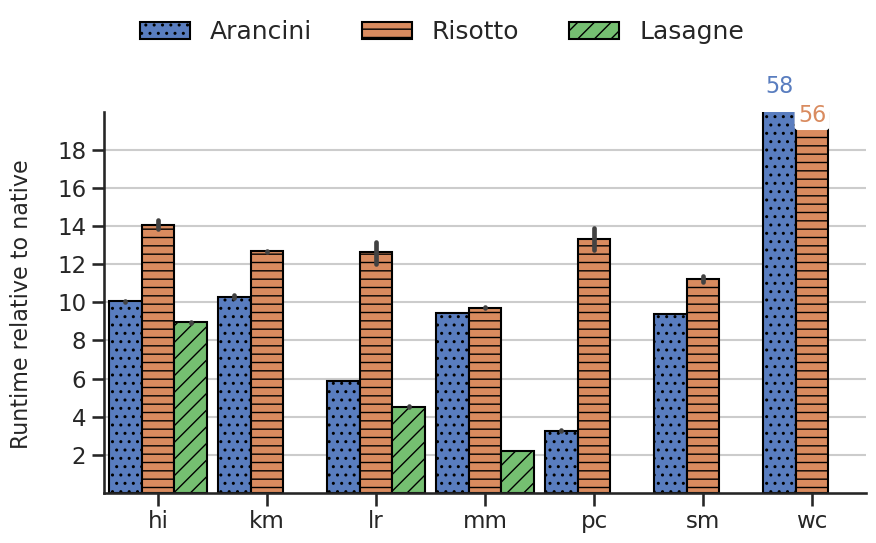

In [18]:

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["figure.labelsize"] = 16
#mpl.rcParams["figure.figsize"] = (7,3)
#fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(7, 3), sharex=True)
#fig.subplots_adjust(hspace=0.05)

sns.set_style("whitegrid")
#sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
#sns.set_context("paper", rc={"font.size": 5, "axes.titlesize": 5, "axes.labelsize": 8})

sns.set_style("ticks", {"xtick.major.size": 14, "ytick.major.size": 14, "axes.grid":True})
sns.set_context("talk", rc={"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14})

dat = data.copy()
dat.drop(dat[dat["emulator"]=="arancini"].index, inplace=True)
dat.drop(dat[dat["emulator"]=="risotto"].index, inplace=True)

dat.drop(dat[dat["variant"]=="map-reduce"].index, inplace=True)
dat.drop(dat[dat["version"]=="RISC-V"].index, inplace=True)

dat["emulator"] = dat["emulator"].apply(lambda l: "Arancini" if l=="arancini+nlib" else l)
dat["emulator"] = dat["emulator"].apply(lambda l: "Risotto" if l=="risotto+nlib" else l)
dat["emulator"] = dat["emulator"].apply(lambda l: "Lasagne" if l=="lasagne" else l)
grid = sns.catplot(data=dat[dat["threads"]==16],row="version", col="variant", kind="bar", height=1,
                   aspect=1, x="short", y="normalized_time_native", hue="emulator",
                   palette=cp, estimator=gmean, width=0.9, edgecolor="black")
#sns.barplot(data=scale[0][scale[0]["threads"] == 16], x="short", y="normalized_time", hue="emulator", palette="pastel", ax=ax1, estimator="median", width=0.5, edgecolor="black")
#sns.barplot(data=scale[1][scale[1]["threads"] == 16], x="short", y="normalized_time", hue="emulator", palette="pastel", ax=ax2, estimator="median", width=0.5, edgecolor="black", legend=False)


grid.set_axis_labels("", "")
#grid.set_titles("{row_name}: {col_name}")
grid.set_titles("")

fig = grid.figure
fig.supylabel("Runtime relative to native")
axs = grid.axes.flatten()

for a in axs:
    a.set_ylim(0, 20)
grid.set(yticks=np.arange(2,20,2))

#axs[1].spines.left.set_visible(False)
#axs[1].tick_params(axis='y', which='both', left=False)
#axs[3].spines.left.set_visible(False)
#axs[3].tick_params(axis='y', which='both', left=False)

#ax2.spines.top.set_visible(False)
#ax1.tick_params(axis='x', which='both', bottom=False, top=False, labelbottom=False)
#ax2.xaxis.tick_bottom()

#ax2.set_xticklabels(scale[0]["short"].unique(), rotation=0)
    # ax.legend(loc="upper left", title=None, fontsize=FONTSIZE,
    #           bbox_to_anchor=(-0.02, 1.0))
    # place legend below the graph

#ax2.set_ylabel("Runtime Relative to Native")
#ax2.yaxis.set_label_coords(-0.05, 1.2) 
#ax2.set_xlabel("")
#ax1.set_ylabel("")
#ax1.set_xlabel("")


#d = .5  # proportion of vertical to horizontal extent of the slanted line
#kwargs = dict(marker=[(-1, -d), (1, d)], markersize=12,
#              linestyle="none", color='k', mec='k', mew=1, clip_on=False)
#ax1.plot([0, 1], [0, 0], transform=ax1.transAxes, **kwargs)
#ax2.plot([0, 1], [1, 1], transform=ax2.transAxes, **kwargs)

#hatches = ["/", "-", "o", "\\", "---", ".", "x"]
hatches = ["..", "--", "//", "\\\\", "xx", "OO"]

bars = []
for ax in axs:
    for p in ax.patches:
        bars.append(p)

handles = grid.legend.get_patches()
#bars = ax1.patches
#handles = ax1.get_legend().get_patches()
l = len(handles)

hs = []
hmap = {}

i=0

texts = []
for j,bar in enumerate(bars):
    if bar.get_facecolor() not in hmap.keys():
        hmap[bar.get_facecolor()] = hatches[i]
        i=i+1
    bar.set_hatch(hmap[bar.get_facecolor()])

    if bar.get_height() >= 22:
        texts.append(bar.axes.text(bar.get_x()+bar.get_width()/2.0, 21-1.5*list(hmap.keys()).index(bar.get_facecolor()),
                      str(int(bar.get_height())), backgroundcolor=None, fontsize=16,
                      bbox={"boxstyle":"round", "pad":0.1, "fc":"w"},
                      ha="center", rotation="horizontal", color=bar.get_facecolor()))



#for b in ax2.patches:
#    b.set_hatch(hmap[b.get_facecolor()])

for h in handles:
    h.set_hatch(hmap[h.get_facecolor()])

#leg = ax1.get_legend()
leg = grid.legend
old_handles = leg.get_patches()
old_labels = list(map(lambda t: t.get_text(), leg.get_texts()))

leg.remove()

grid.add_legend(
    #old_handles,
    #old_labels,
    loc="lower center",
    title=None,
    fontsize=18,
    bbox_to_anchor=(0.5, 0.975),
    ncol=5,
    frameon=False,
)

#ax2.axhline(y=1, color="black", linewidth=1)

fig.set_size_inches((9, 5))
fig.tight_layout()

plt.savefig("phoenix.png", dpi=500, bbox_inches="tight")
#plt.savefig("phoenix.pdf", bbox_inches="tight")


In [22]:
for ax in axs:
    for p in ax.lines:
        p.set_visible(False)

for t in texts:
        t.set_visible(False)

for ax in axs:
    for p in ax.patches:
        p.set_visible(False)


fig.savefig("phoenix-empty.png", dpi=500, bbox_inches="tight")

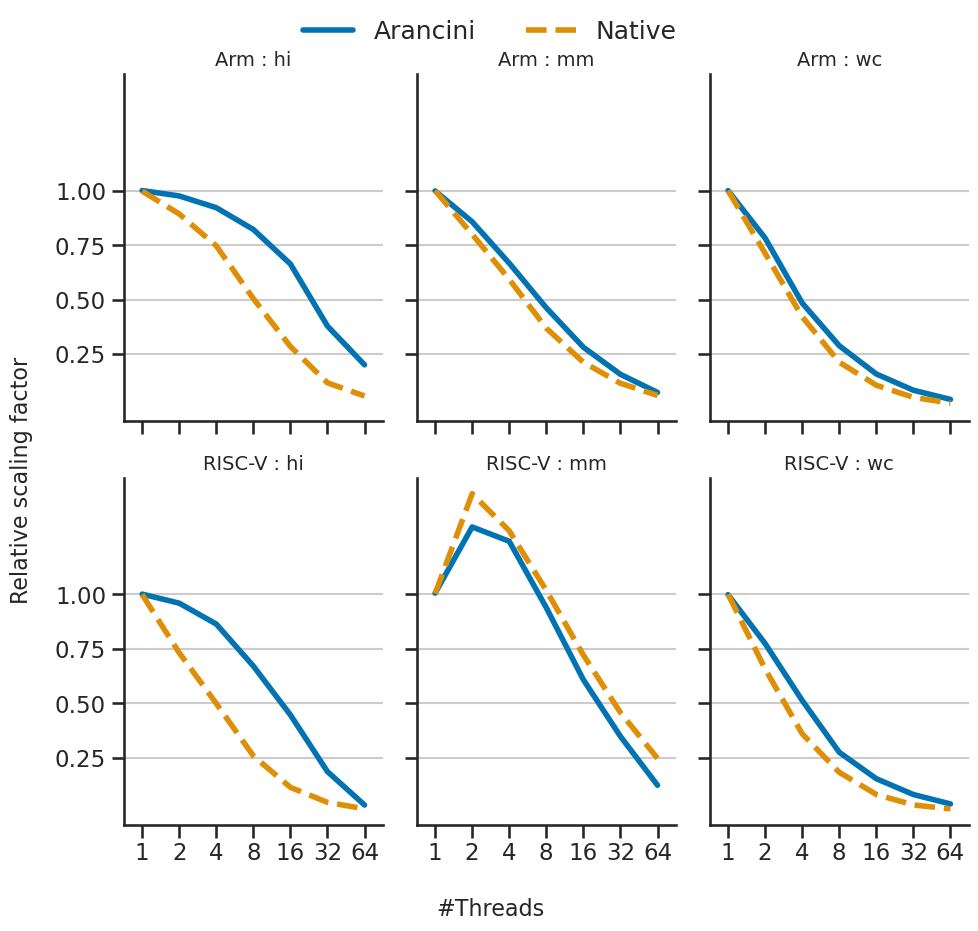

In [7]:
out = ["risotto", "risotto+nlib", "lasagne", "arancini+nlib"]
ob = ["km", "lr", "sm", "pc"]
#data2=data.copy()

sns.set_style("whitegrid")
#sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
#sns.set_context("paper", rc={"font.size": 5, "axes.titlesize": 5, "axes.labelsize": 8})

sns.set_style("ticks", {"xtick.major.size": 14, "ytick.major.size": 14, "axes.grid":True})
sns.set_context("talk", rc={"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14})

for o in out:
    data2.drop(data2[data2["emulator"]==o].index, inplace=True)

for o in ob:
    data2.drop(data2[data2["short"]==o].index, inplace=True)
#tf = tf.groupby(["benchmark", "emulator"], as_index=False)[tf.columns].apply(inv_normalize, 1, "threads")
#tf["short"] = tf["benchmark"].apply(lambda l: l[0:2])
#tf.sort_values(by=["emulator", "benchmark"], key=to_idx, inplace=True)

#fig, ax = plt.subplots(1, figsize=(7, 3), sharex=True)
data2["emulator"] = data2["emulator"].apply(lambda l: "Arancini" if l=="arancini" else l)
data2["emulator"] = data2["emulator"].apply(lambda l: "Native" if l=="native" else l)

#grid = sns.catplot(data=tf, x="threads", height=3, aspect=0.16, y="normalized_time", kind="bar", col="short", hue="emulator",edgecolor="black", palette="pastel", estimator="median")
grid = sns.catplot(data=data2,row="version", col="short", kind="point",
                   linestyles=["solid", "dashed", "dotted"], height=4, aspect=2,
                   x="threads", y="normalized_time_1", hue="emulator", palette="colorblind",
                   estimator=gmean, markers=None, errorbar=None, linewidth = 4)#, edgecolor="black")

grid.set_axis_labels("", "")
grid.set_titles("{row_name} : {col_name}")

#grid.set(xticks=["1","2","8","64"])
grid.set(yticks=[0.25, 0.5, 0.75, 1])

fig = grid.figure

fig.supxlabel("#Threads")

axs = grid.axes.flatten()

bars = []
for ax in axs:
    for p in ax.patches:
        bars.append(p)

handles = grid.legend.get_patches()
l = len(handles)

hs = []
hmap = {}

i=0
for bar in bars:
    if bar.get_facecolor() not in hmap.keys():
        hmap[bar.get_facecolor()] = hatches[i]
        i=i+1
    #bar.set_hatch(hmap[bar.get_facecolor()])


#for b in bars:
#    b.set_hatch(hmap[b.get_facecolor()])

#for h in handles:
#    h.set_hatch(hmap[h.get_facecolor()])

leg = grid.legend
old_handles = handles
old_labels = list(map(lambda t: t.get_text(), leg.get_texts()))

leg.remove()

fig.legend(
    #legend_data=list(zip(old_handles,old_labels)),
    loc="lower center",
    title=None,
    fontsize=18,
    bbox_to_anchor=(0.5, 0.96),
    ncol=3,
    frameon=False,
)

fig.supylabel("Relative scaling factor")
fig.set_size_inches((10, 9))
fig.tight_layout()

grid.savefig("scaling.png", dpi=500)
#grid.savefig("scaling_full.pdf", bbox_inches="tight")

In [8]:

for i in [0,1]:
    scale[i] = scale[i].groupby(["benchmark", "threads"], as_index=False)[scale[i].columns].apply(normalize, "risotto", "emulator")
    scale[i]["normalized_time_risotto"] = scale[i]["normalized_time_risotto"].apply(lambda l: 1/l)
    #print(scale[i].groupby(["emulator", "version"], as_index=False)["normalized_time_risotto"].apply(gmean))
    #print(scale[i].groupby(["emulator", "version"], as_index=False)["normalized_time_risotto"].max())

#print("#########")
#for i in [0,1]:
    #print(scale[i][scale[i]["threads"] == 16 ].groupby(["emulator", "version"], as_index=False)["normalized_time_risotto"].apply(gmean))
    #print(scale[i][scale[i]["threads"] == 16 ].groupby(["emulator", "version"], as_index=False)["normalized_time_risotto"].max())

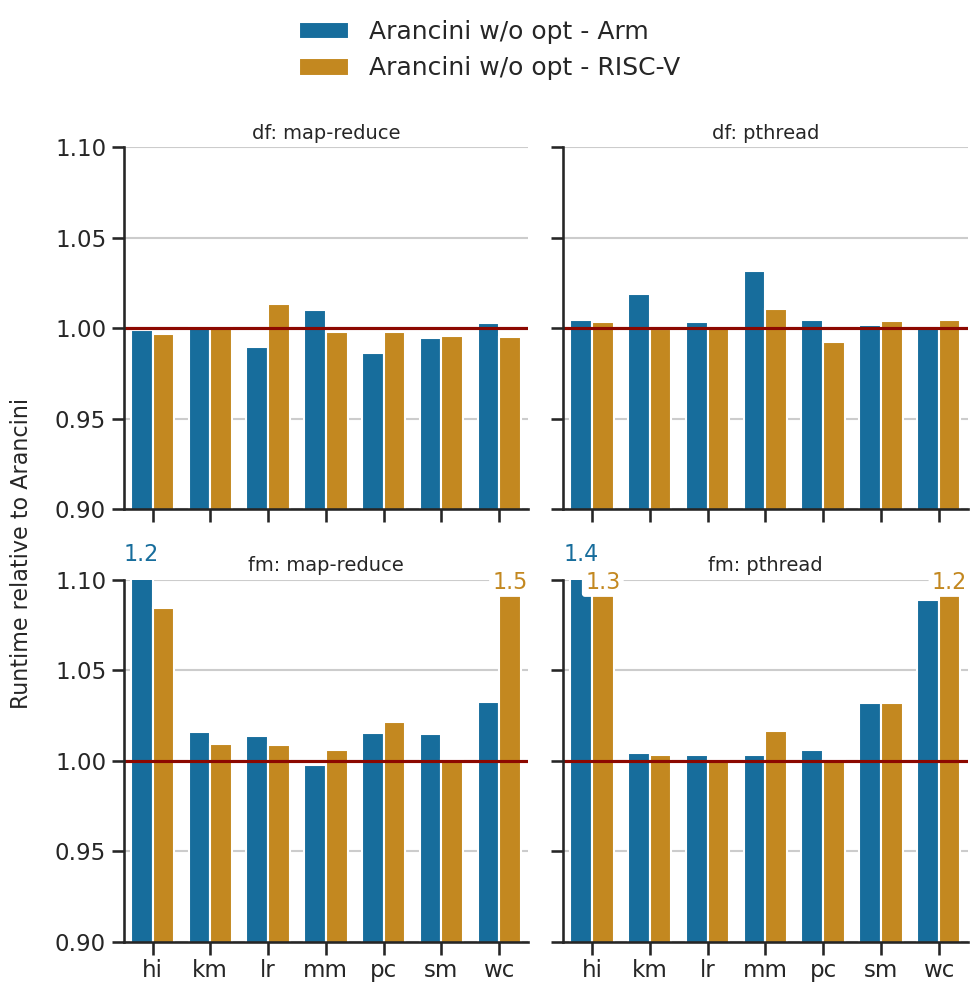

In [9]:
dota = pd.concat(opt, ignore_index=True)
fm = dota.copy()

fm.drop(fm[fm["emulator"]=="native"].index, inplace=True)
#fm.drop(fm[fm["emulator"]=="arancini-no-df"].index, inplace=True)
fm.drop(fm[fm["emulator"]=="arancini-no-df+nlib"].index, inplace=True)
fm.drop(fm[fm["emulator"]=="arancini-no-fm+nlib"].index, inplace=True)
fm.drop(fm[fm["emulator"]=="arancini+nlib"].index, inplace=True)

tmp = fm[fm["emulator"]=="arancini"]

def to_opt(e):
    if "df" in e:
        return "df"
    if "fm" in e:
        return "fm"
    return ""

def adj_name(e):
    if "df" in e:
        return "Arancini w/o opt"
    if "fm" in e:
        return "Arancini w/o opt"
    return "Arancini w/ opt"
    
fm["name"] = fm[["emulator", "version"]].apply(lambda l: f'{adj_name(l["emulator"])} - {l["version"]}', axis=1)
fm["opt"] = fm["emulator"].apply(to_opt)

based = fm[fm["opt"]==""]
b1 = based.copy()
b1["opt"] = "df"
b2 = based.copy()
b2["opt"] = "fm"

fm.drop(based.index, inplace=True)
fm = pd.concat([fm, b1, b2], ignore_index=True)

fm = fm.groupby(["benchmark", "threads", "version", "variant"], as_index=False)[fm.columns].apply(normalize, "arancini", "emulator")
fm.sort_values(by=["emulator", "benchmark"], key=to_idx, inplace=True)


fm.drop(fm[fm["emulator"]=="arancini"].index, inplace=True)
#fig, ax = plt.subplots(1, figsize=(3.5, 3), sharex=True)

sns.set_style("whitegrid")
#sns.set_style("ticks", {"xtick.major.size": 8, "ytick.major.size": 8})
#sns.set_context("paper", rc={"font.size": 5, "axes.titlesize": 5, "axes.labelsize": 8})

sns.set_style("ticks", {"xtick.major.size": 14, "ytick.major.size": 14, "axes.grid":True})
sns.set_context("talk", rc={"font.size": 14, "axes.titlesize": 16, "axes.labelsize": 14})

#ax = sns.barplot(ax=ax, data=fm, x="short", y="normalized_time", hue="emulator",edgecolor="black", palette="pastel", estimator="median", width=0.5)

grid = sns.catplot(data=fm, row="opt", col="variant", kind="bar", height=4, aspect=2,
                   x="short", y="normalized_time_arancini", hue="name", palette="colorblind",
                   estimator="median", errorbar=None, width=0.75, edgecolor=None)



grid.set_axis_labels("", "")
grid.set_titles("{row_name}: {col_name}")

fig = grid.figure

axs = grid.axes.flatten()

mut = sns.color_palette(palette="dark")

for a in axs:
    a.axhline(1, color=mut[3])
    a.set_ylim(0.9, 1.1)

bars = []
for ax in axs:
    for p in ax.patches:
        bars.append(p)

handles = grid.legend.get_patches()
l = len(handles)

hs = []
hmap = {}

i=0
for bar in bars:
    if bar.get_facecolor() not in hmap.keys():
        hmap[bar.get_facecolor()] = hatches[i]
        i=i+1
    #bar.set_hatch(hmap[bar.get_facecolor()])
    if bar.get_height() >= 1.1:
        bar.axes.text(bar.get_x()+0.5*bar.get_width(),
                      1.11-0.015*list(hmap.keys()).index(bar.get_facecolor()),
                      str(round(bar.get_height(), 1)),
                      backgroundcolor="w", fontsize=16, bbox={"boxstyle":"round", "pad":0.1, "fc":"w"},
                      ha="center", color=bar.get_facecolor())


#for h in handles:
#    h.set_hatch(hmap[h.get_facecolor()])


leg = grid.legend
old_handles = handles
old_labels = list(map(lambda t: t.get_text(), leg.get_texts()))

leg.remove()

fig.legend(
    #legend_data=list(zip(old_handles,old_labels)),
    loc="lower center",
    title=None,
    fontsize=18,
    bbox_to_anchor=(0.5, 1),
    ncol=1,
    frameon=False,
    #bbox_transform=fig.get_transform()
    #mode="expand"
)

fig.supylabel("Runtime relative to Arancini")
fig.set_size_inches((10, 9))
fig.tight_layout()

plt.savefig("opt-full.png", dpi=500, bbox_inches="tight")
#plt.savefig("opt-full.pdf", bbox_inches="tight")

In [10]:
csvfile = open("../../bench/llock/times.csv", "r")
lock = pd.read_csv(csvfile)

lock = lock.groupby(["benchmark"], as_index=False)[lock.columns].apply(normalize, "native", "emulator")
lock.groupby(["emulator", "benchmark"])["normalized_time_native"].mean()

emulator  benchmark     
arancini  arraylock          3.345531
          caslock            3.501924
          clhlock            3.550122
          cnalock            3.469846
          hclhlock           3.502628
          hemlock            3.485141
          hmcslock           3.511097
          lockref            3.113239
          mcslock            3.522153
          rec_mcslock        3.562753
          rec_seqlock        3.450740
          rec_spinlock       3.554469
          rec_ticketlock     3.553998
          rwlock             3.507211
          seqlock            3.491322
          ticketlock         3.513766
          ttaslock           3.588372
          twalock            3.545228
native    arraylock          1.073004
          caslock            1.103093
          clhlock            1.115012
          cnalock            1.114409
          hclhlock           1.111134
          hemlock            1.112093
          hmcslock           1.113646
          lockref        